In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
cwd = Path.cwd()

In [2]:
model_number = 5
trial_number = 4

trial_dir = f"model_v{model_number}_test_{trial_number}"


DATA_DIR = cwd.parent / "test" / trial_dir
DATA_FILE = DATA_DIR / "test.csv"

In [3]:
df = pd.read_csv(DATA_FILE, low_memory=False)
df.head(5)

,epoch,train_bg_rmse,train_bg_mae,train_bg_r2,train_bg_r2-semi,train_fe_rmse,train_fe_mae,train_fe_r2,train_metal_acc,test_bg_rmse,test_bg_mae,test_bg_r2,test_bg_r2-semi,test_fe_rmse,test_fe_mae,test_fe_r2,test_metal_acc,loss
0,1,1.158727,0.888533,0.353193,0.204385,0.589050,0.471923,0.625550,0.841072,1.155493,0.883501,0.355525,0.223693,0.586484,0.469867,0.626960,0.839306,0.257847
1,2,0.993924,0.747407,0.524097,0.412631,0.548089,0.439588,0.675816,0.831615,0.999057,0.751416,0.518217,0.411202,0.546594,0.437135,0.675980,0.836177,0.205795
2,3,1.021960,0.756547,0.496870,0.370337,0.436255,0.342101,0.794614,0.797981,1.048762,0.777688,0.469085,0.351195,0.436886,0.342447,0.792995,0.802048,0.222513
3,4,0.964399,0.725031,0.551951,0.462803,0.424731,0.334227,0.805322,0.915167,0.990845,0.738339,0.526104,0.444865,0.418148,0.329577,0.810372,0.917804,0.176330
4,5,0.959491,0.704934,0.556499,0.442342,0.323731,0.255667,0.886901,0.877053,0.978572,0.718192,0.537771,0.431047,0.323231,0.257602,0.886690,0.872298,0.176363


In [4]:
import matplotlib.pyplot as plt

In [16]:
def graph_metric(metric, split="both"):
    """
    Plot train/test metrics for band gap and formation energy.

    Args:
        df      : DataFrame with epoch_results rows
        metric  : 'mae', 'rmse', 'r2', or 'r2-semi'
        split   : 'train', 'test', or 'both' (default)
    """
    metric = metric.lower()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    targets = [
        ("bg", "Band Gap",         "royalblue",   "cornflowerblue"),
        ("fe", "Formation Energy",  "forestgreen", "mediumseagreen"),
    ]

    for ax, (key, title, train_color, test_color) in zip(axes, targets):
        if metric == "r2-semi" and key == "fe": continue
        
        if split in ("train", "both"):
            ax.plot(
                df["epoch"], df[f"train_{key}_{metric}"],
                label=f"Train {metric.upper()}",
                color=train_color, linewidth=2, linestyle="--"
            )
        if split in ("test", "both"):
            ax.plot(
                df["epoch"], df[f"test_{key}_{metric}"],
                label=f"Test {metric.upper()}",
                color=test_color, linewidth=2
            )

        ax.set_title(f"{title} ({metric.upper()})", fontsize=14)
        ax.set_xlabel("Epoch", fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.7)
        ax.legend()

    plt.suptitle(f"Model Performance — {metric.upper()}", fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def graph_loss():
    """
    Plot the training loss curve.

    Args:
        df : DataFrame with epoch_results rows
    """
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(df["epoch"], df["loss"], color="darkorange", linewidth=2, label="Train Loss")
    ax.set_title("Training Loss", fontsize=14)
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Loss", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)
    ax.legend()

    plt.tight_layout()
    plt.show()

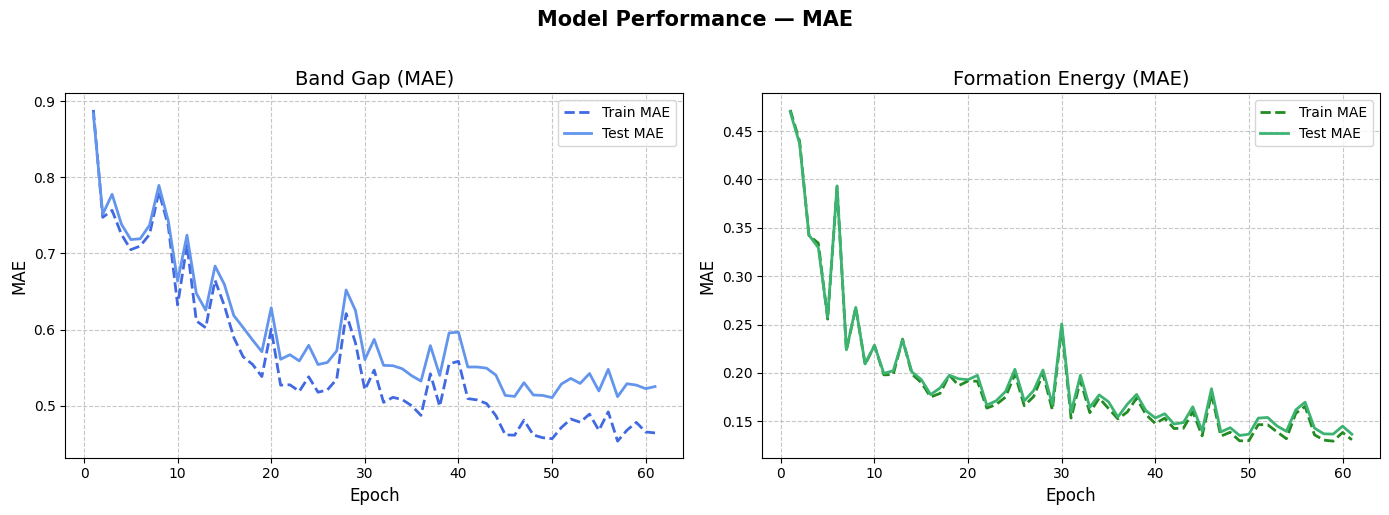

In [6]:
graph_metric('mae')

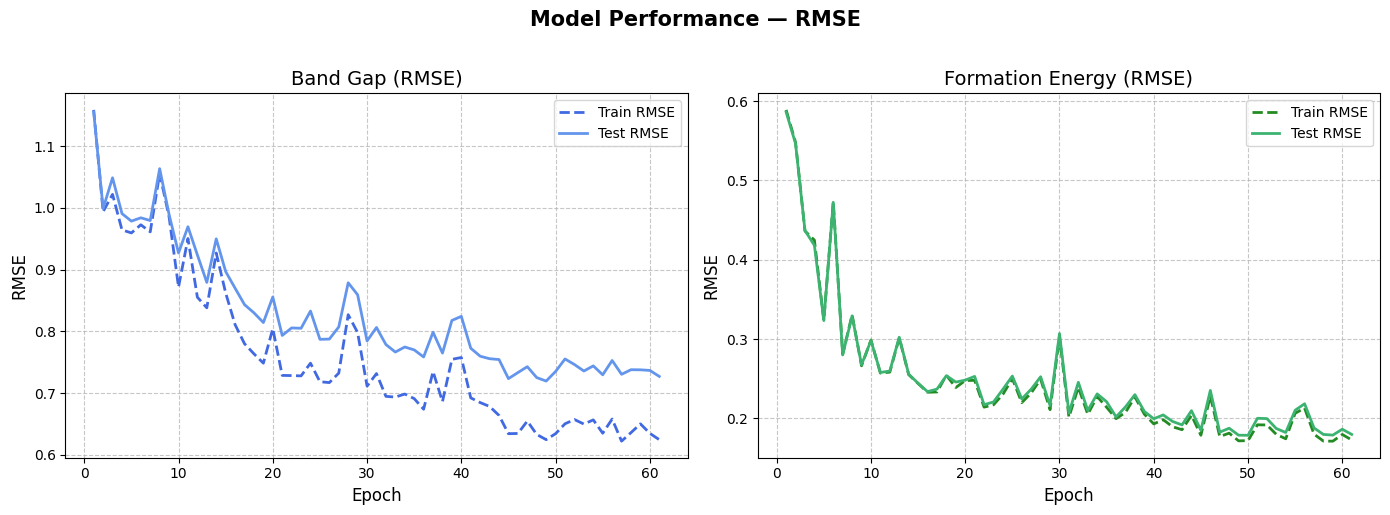

In [7]:
graph_metric('rmse')

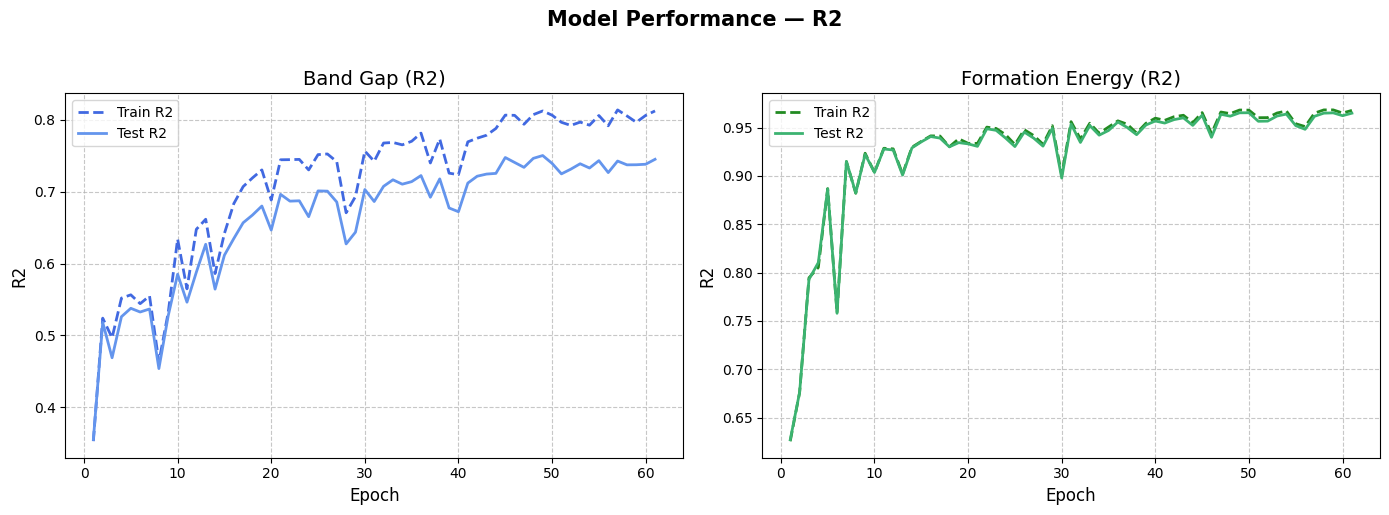

In [8]:
graph_metric('r2')

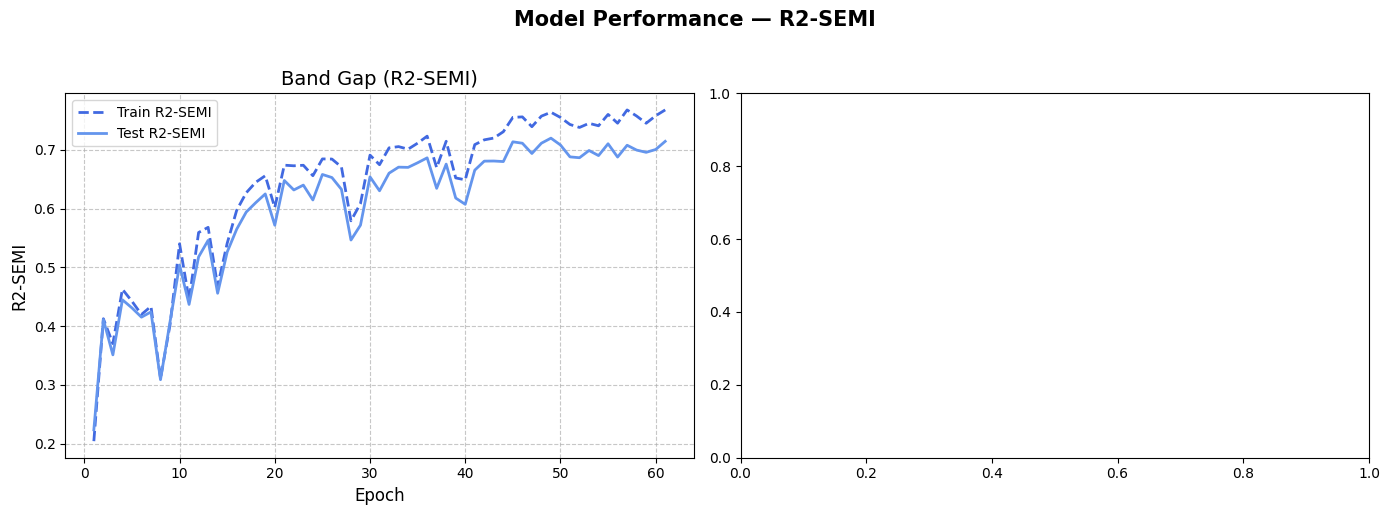

In [17]:
graph_metric('r2-semi')

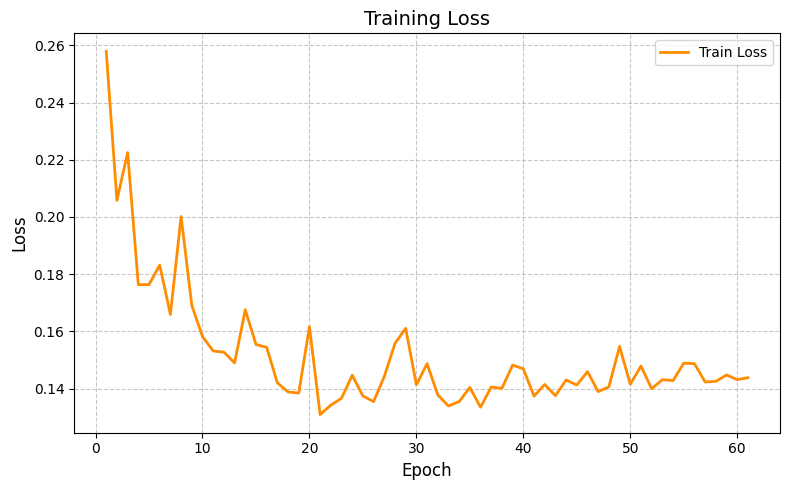

In [9]:
graph_loss()

In [10]:
def plot_scatter_with_fit(ax, x, y):
    all_vals = np.concatenate([x, y])
    lims = [min(all_vals.min(), 0), max(all_vals.max(), 1e-6)]
    
    ax.scatter(x, y, alpha=0.5, s=20, color="steelblue", zorder=2)
    ax.plot(lims, lims, "k--", linewidth=1, label="Ideal", zorder=3)

    m, b = np.polyfit(x, y, 1)
    x_fit = np.linspace(lims[0], lims[1], 200)
    ax.plot(x_fit, m * x_fit + b, "r-", linewidth=1.5, label=f"Fit: y={m:.2f}x+{b:.2f}", zorder=4)

    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend(fontsize=8)
    ax.set_aspect("auto", adjustable="box")

In [11]:
def plot_gnn_predictions(df_train, df_test, model_name="GNN Model"):
    """
    Plot actual vs predicted for band gap (bg) and formation energy (fe)
    for both train and test sets.
    
    Args:
        df_train: DataFrame with columns bg_actual, bg_predicted, fe_actual, fe_predicted
        df_test:  Same structure as df_train
        model_name: String label for plot titles
    """
    targets = [
        ("bg_actual",  "bg_predicted",  "Band Gap",         "eV"),
        ("fe_actual",  "fe_predicted",  "Formation Energy", "eV/atom"),
    ]
    splits = [("Train", df_train), ("Test", df_test)]

    fig, axes = plt.subplots(len(targets), len(splits), figsize=(14, 10))
    axes = np.atleast_2d(axes)  # shape: (n_targets, n_splits)

    for row_i, (actual_col, pred_col, target_name, unit) in enumerate(targets):
        for col_j, (split_name, df) in enumerate(splits):
            ax = axes[row_i, col_j]

            x = df[actual_col].to_numpy(dtype=float)
            y = df[pred_col].to_numpy(dtype=float)

            plot_scatter_with_fit(ax, x, y)

            # Metrics
            mae  = np.mean(np.abs(y - x))
            rmse = np.sqrt(np.mean((y - x) ** 2))
            r2   = 1 - np.sum((y - x) ** 2) / np.sum((x - x.mean()) ** 2)

            ax.set_title(
                f"{model_name} — {target_name} ({split_name})\n"
                f"MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}",
                fontsize=10
            )
            ax.set_xlabel(f"Actual {target_name} ({unit})")
            ax.set_ylabel(f"Predicted {target_name} ({unit})")

    plt.tight_layout()
    plt.show()

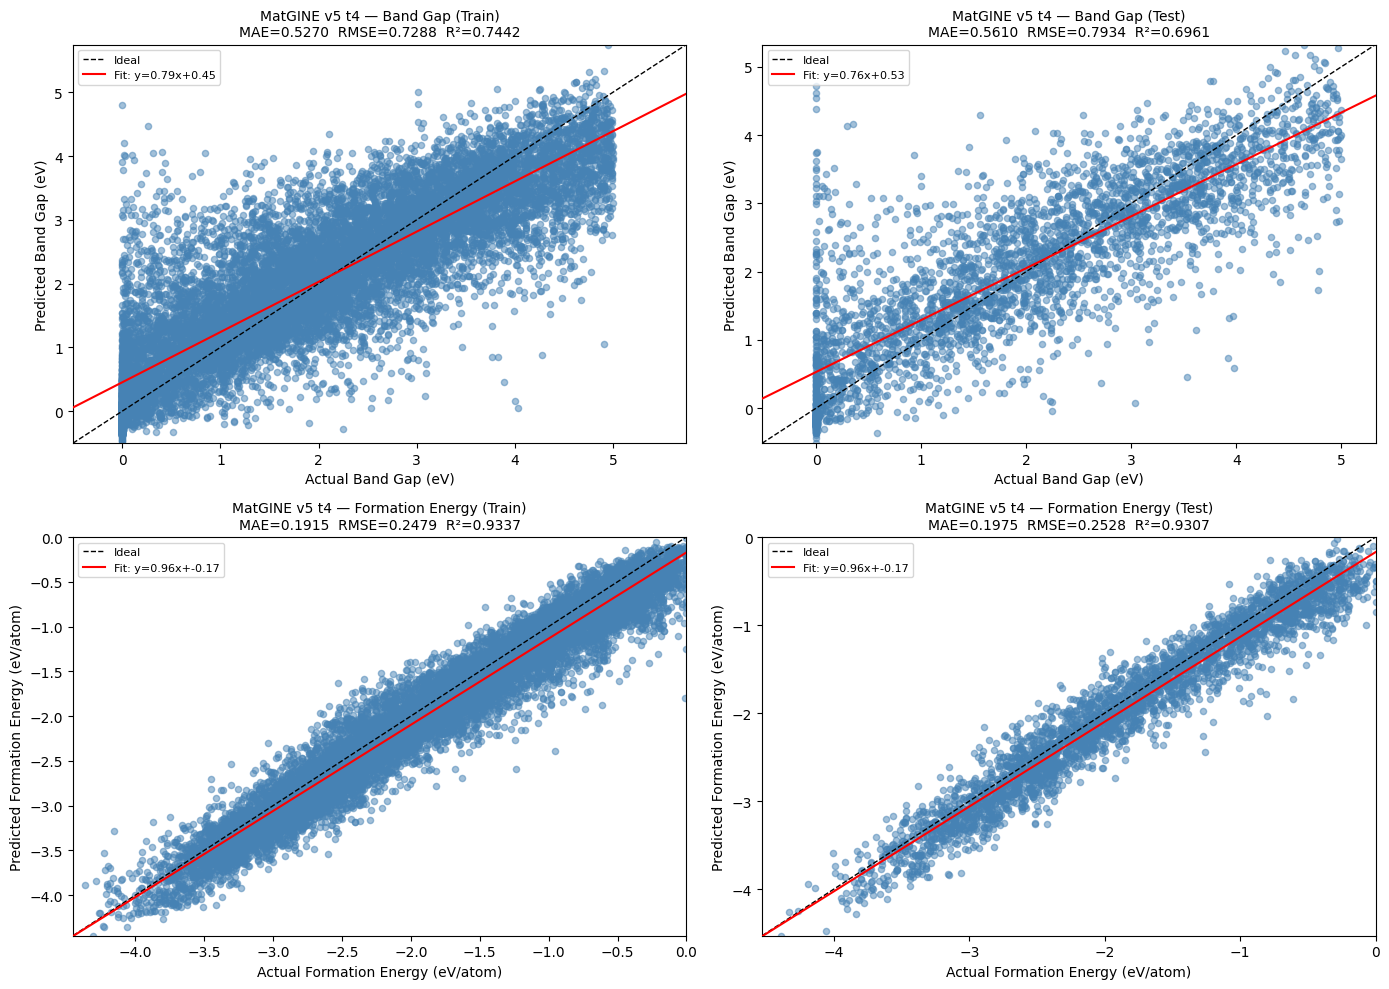

In [12]:
df_train = pd.read_csv(DATA_DIR / "train_predictions_vs_actuals.csv")
df_test  = pd.read_csv(DATA_DIR / "test_predictions_vs_actuals.csv")

plot_gnn_predictions(df_train, df_test, model_name=f"MatGINE v{model_number} t{trial_number}")